## Drinking Fountains for Outdoor Recreation

Having water close by makes exercising, playing sports, or walking outside much easier. I am checking active public drinking fountains across Pittsburgh neighborhoods to see where outdoor hydration is easiest to find.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data.csv")
print("Shape:", df.shape)
print("Feature types:\n", df["feature_type"].value_counts(dropna=False))
print("\nInactive counts:\n", df["inactive"].value_counts(dropna=False))
print("\nMissing neighborhoods:", df["neighborhood"].isna().sum())

Shape: (288, 17)
Feature types:
 feature_type
Drinking Fountain    220
Spray                 56
Decorative             9
NaN                    2
Pond                   1
Name: count, dtype: int64

Inactive counts:
 inactive
False    256
True      32
Name: count, dtype: int64

Missing neighborhoods: 0


I used `data.csv` from the City of Pittsburgh Water Features dataset, which has 288 rows and 67 neighborhoods. Since it includes spray fountains, decorative features, a pond, 2 blank feature types, and 32 inactive (`True`) rows, I filtered to active drinking fountains (`feature_type == "Drinking Fountain"` and `inactive == False`). Every row already had a neighborhood, so I kept all 67 neighborhoods and set missing counts to 0.

In [2]:
df["neighborhood"] = df["neighborhood"].astype(str).str.strip()
all_hoods = sorted(df["neighborhood"].unique())

active_fountains = df[
    (df["feature_type"] == "Drinking Fountain") & (df["inactive"] == False)
].copy()

fountain_counts = (
    active_fountains.groupby("neighborhood")
    .size()
    .reindex(all_hoods, fill_value=0)
    .reset_index(name="fountain_count")
)

max_fountains = fountain_counts["fountain_count"].max()
fountain_counts["fountain_score"] = (
    fountain_counts["fountain_count"] / max_fountains
) * 100

fountain_counts = fountain_counts.sort_values(
    by=["fountain_count", "neighborhood"], ascending=[False, True]
).reset_index(drop=True)

print("Total active drinking fountains:", fountain_counts["fountain_count"].sum())
print(fountain_counts["fountain_count"].describe())
fountain_counts.head(15)

Total active drinking fountains: 192
count    67.000000
mean      2.865672
std       2.713019
min       0.000000
25%       1.000000
50%       2.000000
75%       3.000000
max      14.000000
Name: fountain_count, dtype: float64


,neighborhood,fountain_count,fountain_score
0,Squirrel Hill South,14,100.000000
1,Highland Park,12,85.714286
2,Allegheny Center,8,57.142857
3,Beechview,8,57.142857
4,Perry North,8,57.142857
5,Brookline,7,50.000000
6,Carrick,7,50.000000
7,Elliott,7,50.000000
8,Brighton Heights,6,42.857143
9,Mount Washington,6,42.857143


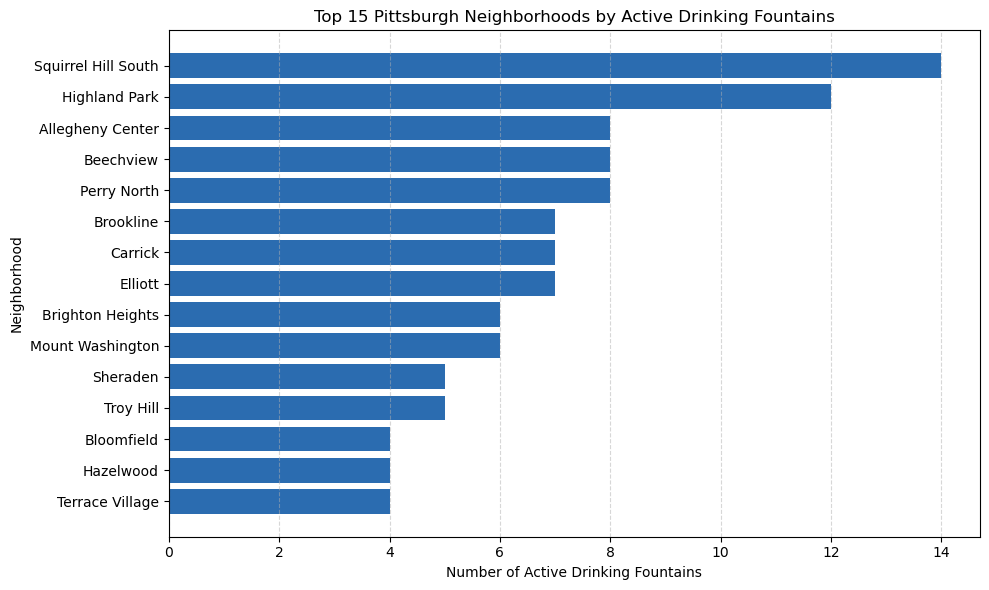

In [3]:
top15 = fountain_counts.head(15).iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(top15["neighborhood"], top15["fountain_count"], color="#2b6cb0")
plt.title("Top 15 Pittsburgh Neighborhoods by Active Drinking Fountains")
plt.xlabel("Number of Active Drinking Fountains")
plt.ylabel("Neighborhood")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

fountain_counts.to_csv("rahul_drinking_fountains.csv", index=False)

Squirrel Hill South (14 active fountains) and Highland Park (12) lead by a wide gap, while most neighborhoods have only 1 to 3. I made a `fountain_score` from 0 to 100 so our team can combine drinking fountains with parks, sports fields, and pools cleanly. One limit is that this shows listed fountains, not seasonal winter shutoffs or water pressure.